# Bank Marketing Campaign Outcomes

**Author:** Mohammed Adeen Shaik

## Research question

Which contact channels and contact-frequency groups have different observed subscription rates?

## Data and evidence

UCI Bank Marketing bank-full.csv, a historical Portuguese bank campaign sample.

Fresh execution on 11 October 2026. The **45,211 contact records** contain **5,289 subscriptions**, an observed conversion rate of **11.70%**. Channel rates vary, but selection differences prevent a causal claim that one channel improves conversion. Month categories pool years; the chart is a calendar-month comparison, not a time trend.

| contact | contacts | conversions | conversion_rate |
|---|---|---|---|
| cellular | 29285 | 4369 | 0.1491890046098685 |
| telephone | 2906 | 390 | 0.1342050929112181 |
| unknown | 13020 | 530 | 0.0407066052227342 |



## Reading guide

Read each explanation before its code cell. Run from top to bottom in the documented working directory. A saved chart is an output snapshot, not proof that this notebook was rerun today. The final section collects findings and visual evidence.

## Method

The subscription label becomes a binary indicator. Grouped counts give conversion numerators and denominators. Calendar month labels combine observations across years and are not a continuous time series.

## Interpretation limits

Call duration is known after the call and must not enter pre-contact targeting. Channel and contact-count differences are observational; they do not measure causal campaign lift.

# Marketing Campaign Performance — Key Visuals

Run the campaign pipeline first. Duration visuals are descriptive only because duration is unavailable before a call ends.

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


### Guide to code step 2

**Load the source table.** A DataFrame is a spreadsheet-like table in memory. The path must point to the documented input file; loading a file does not validate its contents.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed")
contacts = pd.read_csv(DATA / "fact_campaign_contacts.csv")
monthly = pd.read_csv(DATA / "monthly_performance.csv")
channels = pd.read_csv(DATA / "channel_performance.csv")


### Guide to code step 3

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

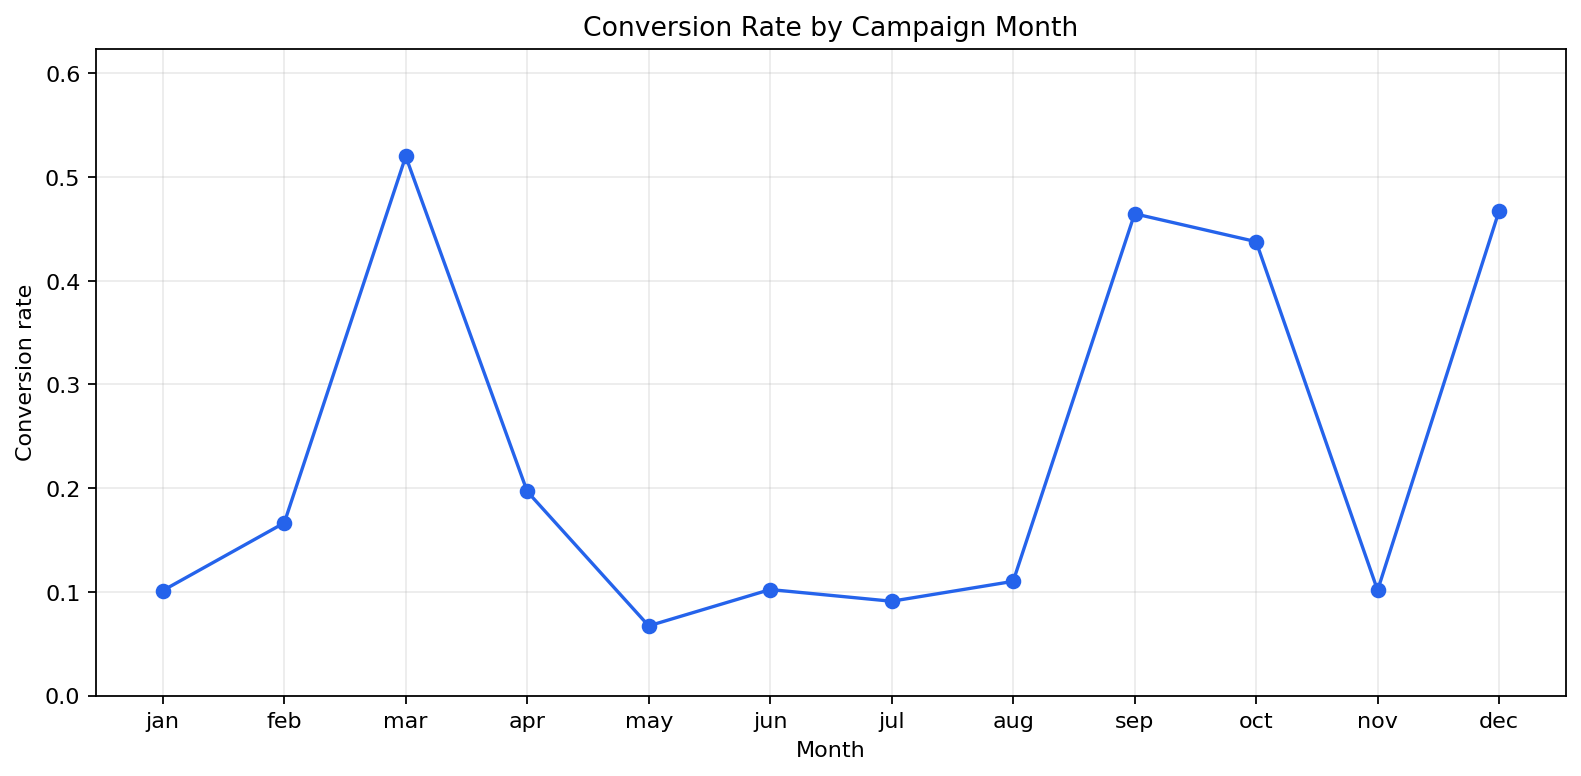

In [2]:
monthly = monthly.sort_values("month_number")
figure, axis = plt.subplots(figsize=(10, 5))
axis.plot(monthly["month"], monthly["conversion_rate"], marker="o", color="#2563EB")
axis.set(title="Conversion Rate by Campaign Month", xlabel="Month", ylabel="Conversion rate", ylim=(0, monthly["conversion_rate"].max() * 1.2))
axis.grid(alpha=0.25)
figure.tight_layout()


### Guide to code step 4

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

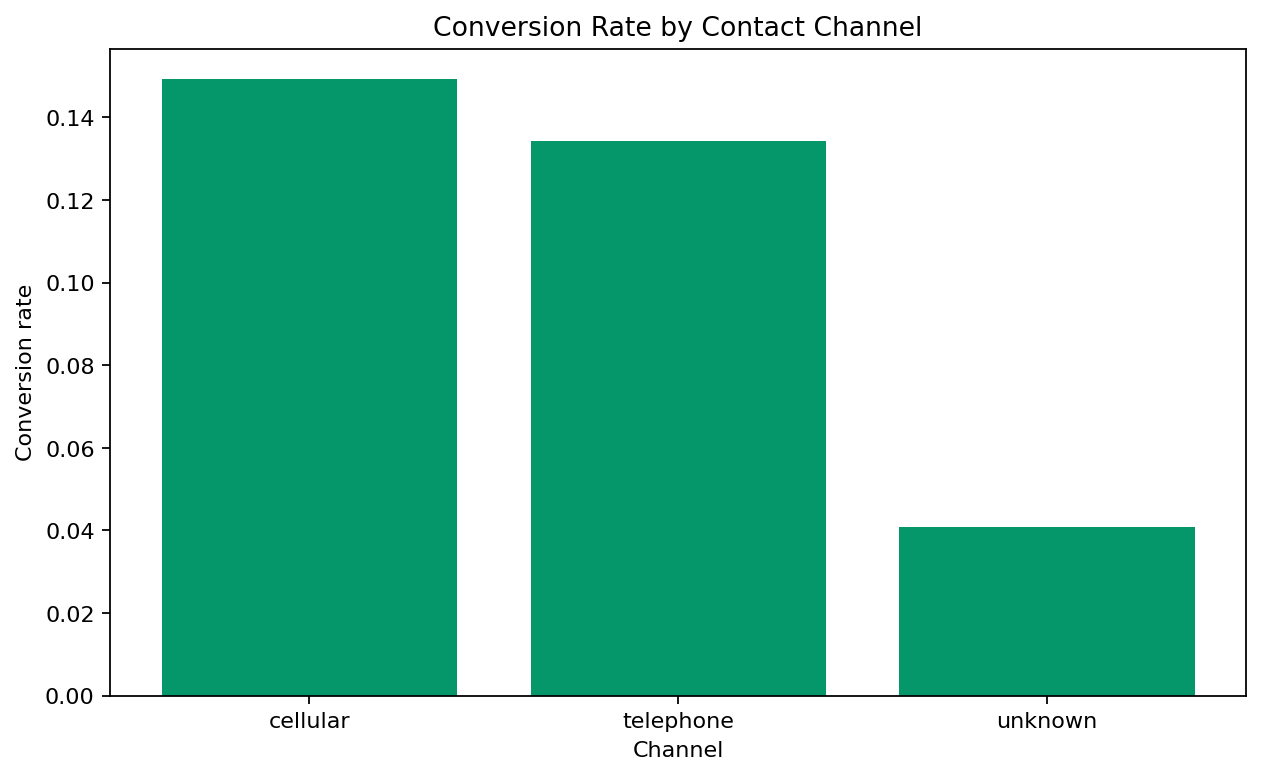

In [3]:
figure, axis = plt.subplots(figsize=(8, 5))
axis.bar(channels["contact"], channels["conversion_rate"], color="#059669")
axis.set(title="Conversion Rate by Contact Channel", xlabel="Channel", ylabel="Conversion rate")
figure.tight_layout()


### Guide to code step 5

**Summarize observations.** Grouping collects rows with the same label. Counts and sums produce totals; a mean of a binary 0/1 indicator gives a rate. Always identify the denominator and keep missing categories visible.

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

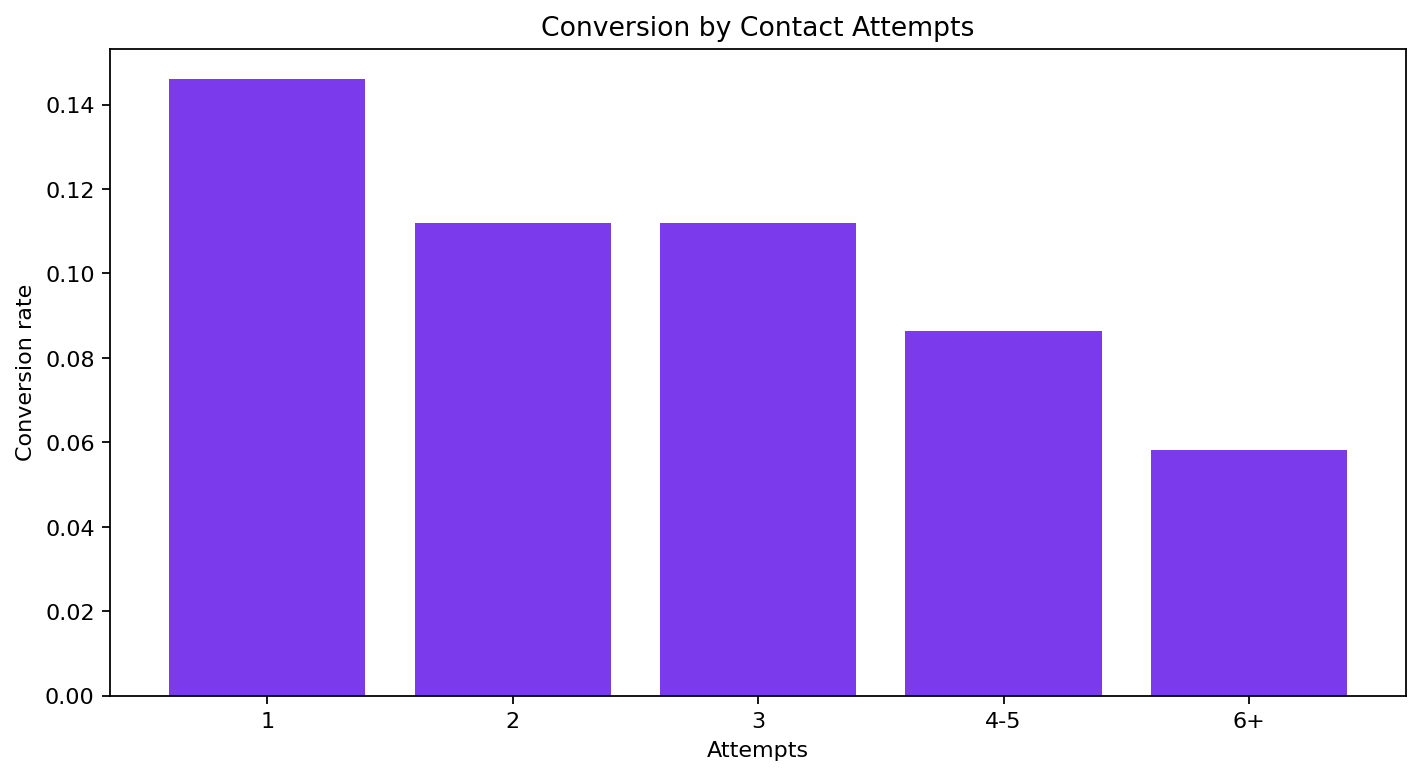

In [4]:
attempts = contacts.groupby("contact_attempt_band", observed=True)["converted"].agg(["count", "mean"]).reset_index()
figure, axis = plt.subplots(figsize=(9, 5))
axis.bar(attempts["contact_attempt_band"].astype(str), attempts["mean"], color="#7C3AED")
axis.set(title="Conversion by Contact Attempts", xlabel="Attempts", ylabel="Conversion rate")
figure.tight_layout()


## Findings and final visual results

Fresh execution on 11 October 2026. The **45,211 contact records** contain **5,289 subscriptions**, an observed conversion rate of **11.70%**. Channel rates vary, but selection differences prevent a causal claim that one channel improves conversion. Month categories pool years; the chart is a calendar-month comparison, not a time trend.

| contact | contacts | conversions | conversion_rate |
|---|---|---|---|
| cellular | 29285 | 4369 | 0.1491890046098685 |
| telephone | 2906 | 390 | 0.1342050929112181 |
| unknown | 13020 | 530 | 0.0407066052227342 |



Call duration is known after the call and must not enter pre-contact targeting. Channel and contact-count differences are observational; they do not measure causal campaign lift.

The following figures are copied from saved notebook outputs or the documented evaluation artifacts. Their source and evidence status are given in the research report.


**Figure from key_visuals.ipynb, original code cell 3**

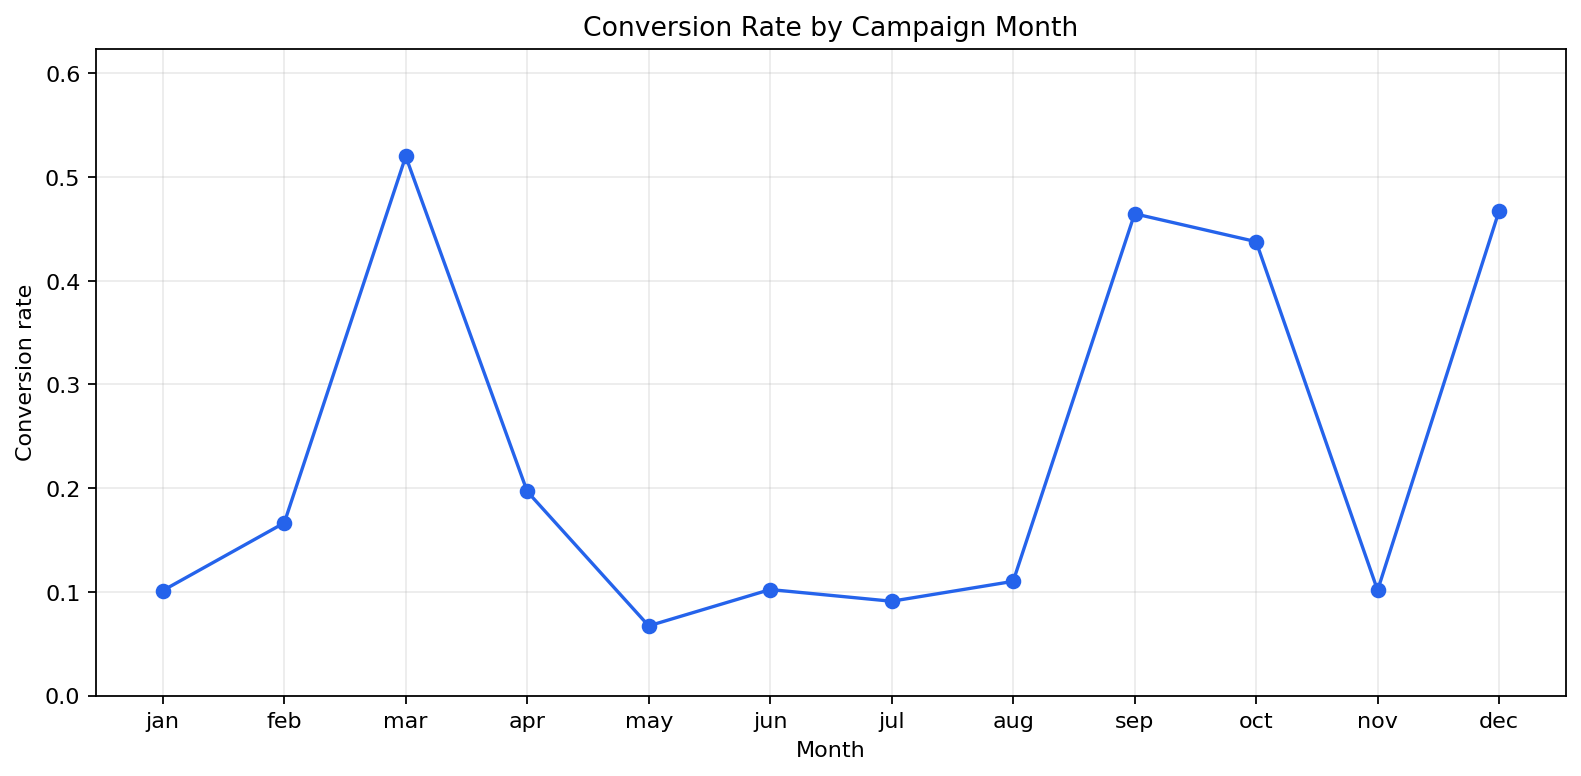

**Figure from key_visuals.ipynb, original code cell 4**

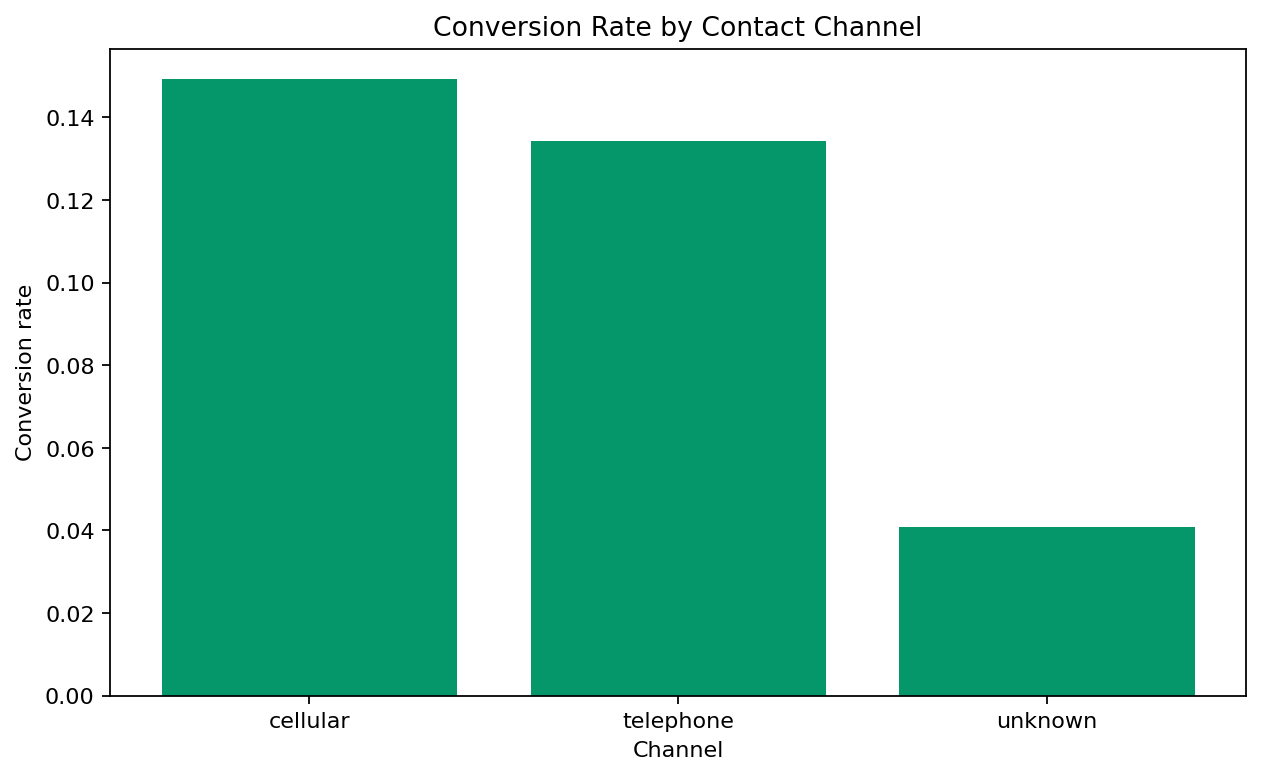

**Figure from key_visuals.ipynb, original code cell 5**

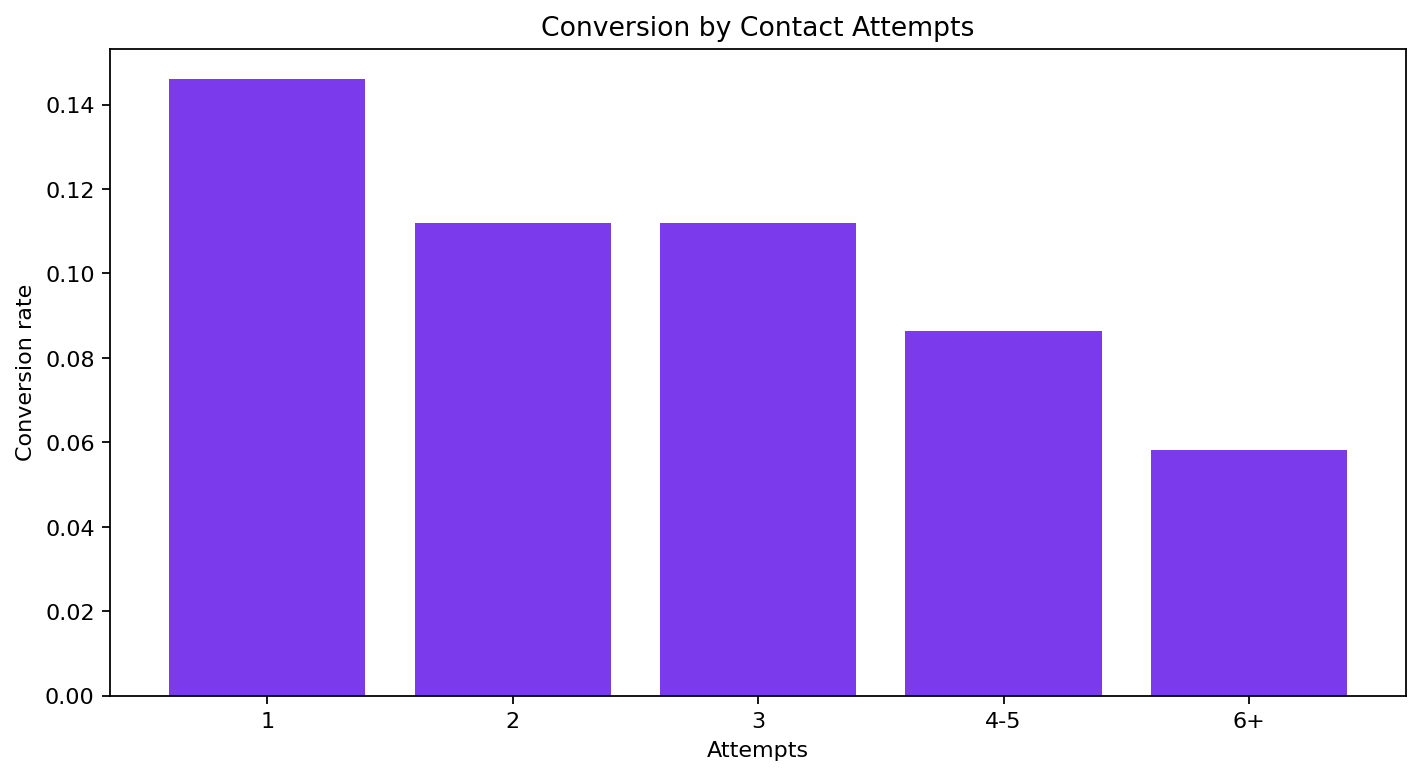